# Calendar Year Tests: Per Diagonal or in Total

In [1]:
import numpy as np
import pandas as pd

import chainladder as cl

`ValuationCorrelation` tests Mack's assumption that no calendar year pushes
a whole diagonal of link ratios up or down. With `total=False` it tests
each diagonal on its own. With `total=True`, the default, it tests one
statistic summed over all diagonals. (`Triangle.valuation_correlation`
defaults to `total=False`.) This example shows how often each form flags
triangles that have no calendar-year effect.

The two forms can disagree. On the paid triangle in `tail_sample`, one
diagonal is flagged at the 10% level:

In [2]:
paid = cl.load_sample("tail_sample")["paid"]
cl.ValuationCorrelation(paid, p_critical=0.1, total=False).z_critical

,2001,2002,2003,2004,2005,2006,2007,2008,2009
2000,False,False,False,False,False,False,False,True,False


The total test on the same triangle does not flag it:

In [3]:
cl.ValuationCorrelation(paid, p_critical=0.1, total=True).z_critical

columns,paid
Total,
Total,False


To see how much weight a lone flag deserves, simulate triangles with no
calendar-year effect by construction: every link ratio is an independent
draw. The test looks only at how link ratios rank within each development
period, so any distribution would do. For each triangle size, count the
share of 1,000 triangles where at least one diagonal is flagged, and the
share flagged by the total test.

In [4]:
def triangles_without_calendar_effect(n_years, n_triangles, rng):
    factors = rng.lognormal(sigma=0.1, size=(n_triangles, n_years, n_years - 1))
    ones = np.ones((n_triangles, n_years, 1))
    cumulative = 1000 * np.cumprod(np.concatenate([ones, factors], axis=2), axis=2)
    origin, age = np.indices((n_years, n_years))
    observed = np.broadcast_to(origin + age < n_years, cumulative.shape)
    sim, i, k = np.nonzero(observed)
    data = pd.DataFrame({
        "triangle": sim,
        "origin": 2000 + i,
        "valuation": 2000 + i + k,
        "loss": cumulative[sim, i, k],
    })
    return cl.Triangle(
        data,
        origin="origin",
        valuation="valuation",
        columns="loss",
        index="triangle",
        cumulative=True,
    )


rng = np.random.default_rng(2026)
rows = []
for n_years in [10, 15, 20, 30]:
    sims = triangles_without_calendar_effect(n_years, 1000, rng)
    per_diagonal = cl.ValuationCorrelation(sims, p_critical=0.1, total=False)
    total = cl.ValuationCorrelation(sims, p_critical=0.1, total=True)
    flags = per_diagonal.z_critical.values[:, 0, 0, :]
    rows.append({
        "Years": n_years,
        "Diagonals": flags.shape[1],
        "Most often flagged diagonal": flags.mean(axis=0).max(),
        "Any diagonal flagged": flags.any(axis=1).mean(),
        "Total test flagged": total.z_critical.values[:, 0].mean(),
    })
false_alarms = pd.DataFrame(rows).set_index("Years")
false_alarms

,Diagonals,Most often flagged diagonal,Any diagonal flagged,Total test flagged
Years,,,,
10,9,0.044,0.151,0.117
15,14,0.066,0.365,0.086
20,19,0.075,0.547,0.106
30,29,0.089,0.768,0.086


No single diagonal is flagged in more than 10% of the triangles. But a
triangle gets one test per diagonal, so the chance that at least one of
them flags grows with its size: about one 10-year triangle in seven, and
more than three 30-year triangles in four. The total test stays near the
10% level at every size.

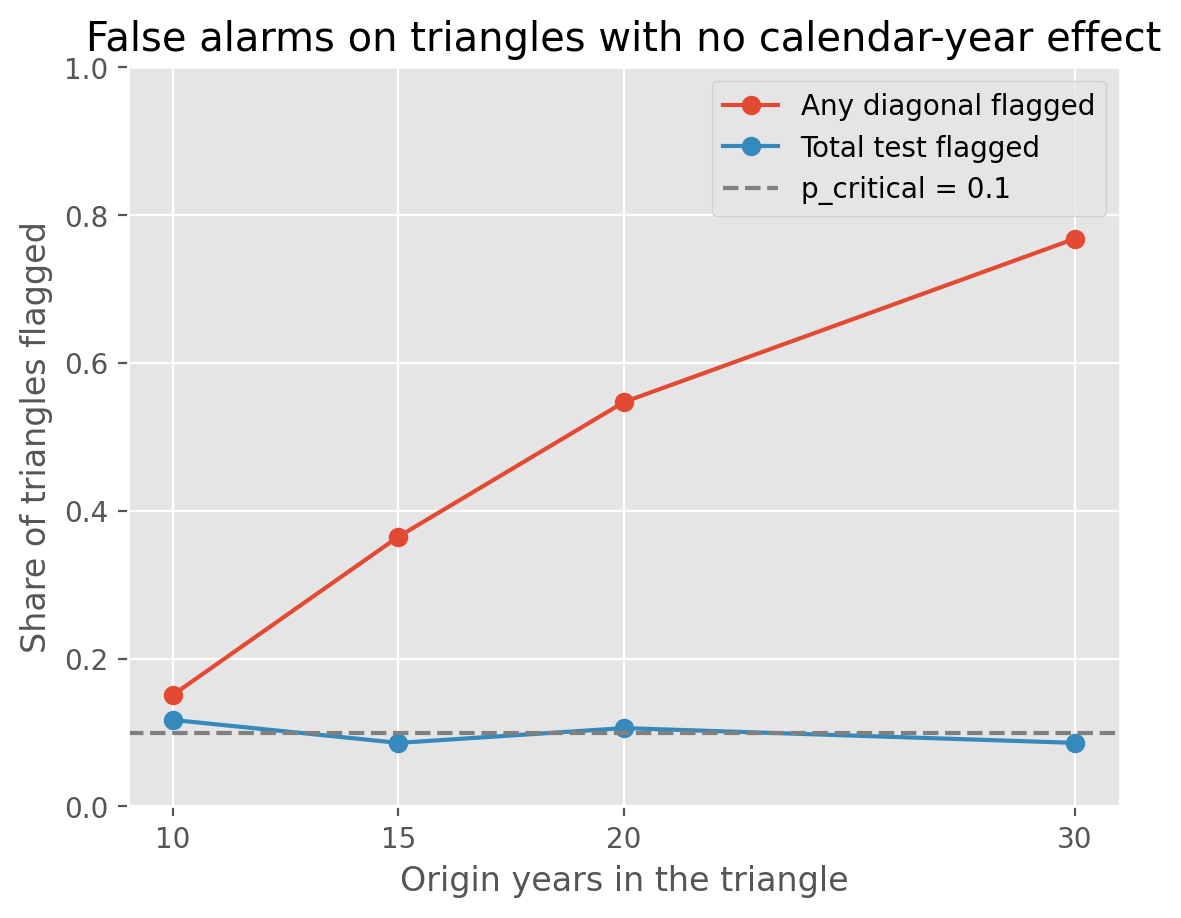

In [5]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

ax = false_alarms[["Any diagonal flagged", "Total test flagged"]].plot(
    marker="o",
    xticks=false_alarms.index,
    ylim=(0, 1),
    title="False alarms on triangles with no calendar-year effect",
    ylabel="Share of triangles flagged",
    xlabel="Origin years in the triangle",
)
ax.axhline(0.1, color="grey", linestyle="--", label="p_critical = 0.1")
ax.legend();

A single `True` in the per-diagonal output is therefore weak evidence on
its own: a flag like the one in the 10-year `tail_sample` triangle turns
up in about one triangle in seven even when there is no calendar-year
effect. Mack tests the total for this reason, since testing each diagonal
separately lets the error probabilities accumulate {cite}`mack1994`.